# Customer Behavior Analysis

## What I want to find out
For this project, I am using the UCI Online Retail dataset to explore customer purchases.

My main question is: **Do customers who buy more than once bring in more revenue than customers who buy only once?**

I will also check how much of the revenue comes from the highest-spending customers.

## 1. Setup

This notebook reads the Excel dataset saved in my project folder. The file should be named `Online Retail.xlsx` and placed in the main project folder.

In [1]:
# If a package is missing, install it from Anaconda Prompt before running the notebook.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

# Find the project folder, even if Jupyter was opened from the notebooks folder.
cwd = Path.cwd()
possible_roots = [cwd, cwd.parent]
known_root = Path(r"C:\Users\lenovo\Downloads\customer_behavior_eda_project\customer_behavior_eda_project")
possible_roots.append(known_root)

PROJECT_DIR = next((root for root in possible_roots if (root / "Online Retail.xlsx").exists()), None)
if PROJECT_DIR is None:
    # Keep a folder path so the next cell can explain if the Excel file is missing.
    PROJECT_DIR = cwd.parent if cwd.name.lower() == "notebooks" else cwd

OUTPUT_DIR = PROJECT_DIR / "outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("Output folder:", OUTPUT_DIR)


Project folder: C:\Users\lenovo\Downloads\customer_behavior_eda_project\customer_behavior_eda_project\notebooks
Output folder: C:\Users\lenovo\Downloads\customer_behavior_eda_project\customer_behavior_eda_project\notebooks\outputs


## 2. Load the data

First, I load the Excel file and look at a few rows to check that it opened correctly.

In [12]:
data_path = PROJECT_DIR / "Online Retail.xlsx"

if not data_path.exists():
    raise FileNotFoundError(
        "Could not find 'Online Retail.xlsx'. Please place it in this folder:\n"
        f"{PROJECT_DIR}\n"
        "Expected file name: Online Retail.xlsx"
    )

df = pd.read_excel(data_path, engine="openpyxl")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())
display(df.head())


Dataset loaded successfully!
Dataset shape: (541909, 8)
Column names: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 3. Check and clean the data

I check for missing customer IDs and duplicate rows. For the sales analysis, I remove duplicates, cancelled invoices, rows with invalid quantity or price, and rows without a customer ID. These choices mean the totals below are based only on the usable sales records.

In [13]:
# Tidy the column names in case there are extra spaces.
df.columns = [str(c).strip().replace(" ", "") for c in df.columns]

required = ["InvoiceNo", "StockCode", "Description", "Quantity",
            "InvoiceDate", "UnitPrice", "CustomerID", "Country"]
missing_cols = [c for c in required if c not in df.columns]
if missing_cols:
    raise ValueError(f"Expected columns not found: {missing_cols}. Available columns: {df.columns.tolist()}")

print("Rows before cleaning:", len(df))
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Missing CustomerID:", int(df["CustomerID"].isna().sum()))

df = df.drop_duplicates().copy()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
for col in ["Quantity", "UnitPrice"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Keep only valid sales rows for this analysis.
invoice_text = df["InvoiceNo"].astype(str).str.strip().str.upper()
valid = (
    ~invoice_text.str.startswith("C")
    & df["CustomerID"].notna()
    & df["InvoiceDate"].notna()
    & df["Quantity"].gt(0)
    & df["UnitPrice"].gt(0)
)
sales = df.loc[valid].copy()
sales["CustomerID"] = sales["CustomerID"].astype(str).str.replace(r"\.0$", "", regex=True)
sales["Revenue"] = sales["Quantity"] * sales["UnitPrice"]
sales["InvoiceMonth"] = sales["InvoiceDate"].dt.to_period("M").astype(str)

print("Rows after cleaning:", len(sales))
print("Customers:", sales["CustomerID"].nunique())
print("Invoices:", sales["InvoiceNo"].nunique())
print("Date range:", sales["InvoiceDate"].min(), "to", sales["InvoiceDate"].max())
print("Total analyzed revenue (£):", round(sales["Revenue"].sum(), 2))


Rows before cleaning: 541909
Exact duplicate rows: 5268
Missing CustomerID: 135080
Rows after cleaning: 392692
Customers: 4338
Invoices: 18532
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Total analyzed revenue (£): 8887208.89


## 4. Look at customer purchases

I count the different invoices for each customer. In this notebook, a repeat customer is someone with more than one invoice in this dataset. Revenue is calculated by multiplying quantity by unit price.

This only covers the dates included in this dataset, so it does not prove that a one-time customer has never bought from the shop before or after this period.

In [14]:
customer_summary = (
    sales.groupby("CustomerID")
    .agg(
        invoices=("InvoiceNo", "nunique"),
        items=("Quantity", "sum"),
        revenue=("Revenue", "sum"),
        first_purchase=("InvoiceDate", "min"),
        last_purchase=("InvoiceDate", "max")
    )
    .reset_index()
)
customer_summary["customer_type"] = np.where(
    customer_summary["invoices"] > 1, "Repeat customer", "One-time customer"
)
customer_summary["average_order_value"] = customer_summary["revenue"] / customer_summary["invoices"]

display(customer_summary.sort_values("revenue", ascending=False).head(10))
display(customer_summary.groupby("customer_type").agg(
    customers=("CustomerID", "count"),
    total_revenue=("revenue", "sum"),
    mean_customer_revenue=("revenue", "mean"),
    median_customer_revenue=("revenue", "median"),
    mean_invoices=("invoices", "mean")
).round(2))


,CustomerID,invoices,items,revenue,first_purchase,last_purchase,customer_type,average_order_value
1689,14646,73,196915,280206.02,2010-12-20 10:09:00,2011-12-08 12:12:00,Repeat customer,3838.438630
4201,18102,60,64124,259657.30,2010-12-07 16:42:00,2011-12-09 11:50:00,Repeat customer,4327.621667
3728,17450,46,69973,194390.79,2010-12-07 09:23:00,2011-12-01 13:29:00,Repeat customer,4225.886739
3008,16446,2,80997,168472.50,2011-05-18 09:52:00,2011-12-09 09:15:00,Repeat customer,84236.250000
1879,14911,201,80240,143711.17,2010-12-01 14:05:00,2011-12-08 15:54:00,Repeat customer,714.980945
55,12415,21,77374,124914.53,2011-01-06 11:12:00,2011-11-15 14:22:00,Repeat customer,5948.310952
1333,14156,55,57768,117210.08,2010-12-03 11:48:00,2011-11-30 10:54:00,Repeat customer,2131.092364
3771,17511,31,64549,91062.38,2010-12-01 10:19:00,2011-12-07 10:12:00,Repeat customer,2937.496129
2702,16029,63,40108,80850.84,2010-12-01 09:57:00,2011-11-01 10:27:00,Repeat customer,1283.346667
0,12346,1,74215,77183.60,2011-01-18 10:01:00,2011-01-18 10:01:00,One-time customer,77183.600000


,customers,total_revenue,mean_customer_revenue,median_customer_revenue,mean_invoices
customer_type,,,,,
One-time customer,1493,613989.56,411.25,255.91,1.00
Repeat customer,2845,8273219.33,2907.99,1154.47,5.99


## 5. Do repeat customers bring in more revenue?

Here I compare the number of repeat and one-time customers with the revenue from each group. I use the percentages printed below as evidence for my finding.

,customers,revenue,average_revenue_per_customer,median_revenue_per_customer,customer_share_pct,revenue_share_pct
customer_type,,,,,,
One-time customer,1493,613989.56,411.25,255.91,34.42,6.91
Repeat customer,2845,8273219.33,2907.99,1154.47,65.58,93.09


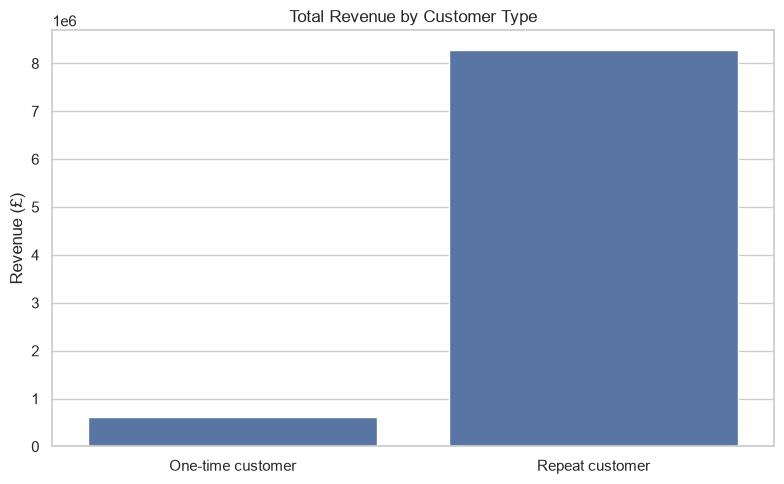

Repeat customers are 65.6% of customers and contribute 93.1% of analyzed revenue.


In [15]:
type_summary = customer_summary.groupby("customer_type").agg(
    customers=("CustomerID", "nunique"),
    revenue=("revenue", "sum"),
    average_revenue_per_customer=("revenue", "mean"),
    median_revenue_per_customer=("revenue", "median")
)
type_summary["customer_share_pct"] = type_summary["customers"] / customer_summary["CustomerID"].nunique() * 100
type_summary["revenue_share_pct"] = type_summary["revenue"] / customer_summary["revenue"].sum() * 100
display(type_summary.round(2))

plt.figure(figsize=(8, 5))
sns.barplot(data=customer_summary, x="customer_type", y="revenue", estimator=np.sum, errorbar=None)
plt.title("Total Revenue by Customer Type")
plt.xlabel("")
plt.ylabel("Revenue (£)")
plt.tight_layout()
plt.savefig(str(FIGURE_DIR / "revenue_by_customer_type.png"), dpi=160)
plt.show()

repeat_rev_share = type_summary.loc["Repeat customer", "revenue_share_pct"] if "Repeat customer" in type_summary.index else 0
repeat_customer_share = type_summary.loc["Repeat customer", "customer_share_pct"] if "Repeat customer" in type_summary.index else 0
print(f"Repeat customers are {repeat_customer_share:.1f}% of customers and contribute {repeat_rev_share:.1f}% of analyzed revenue.")


## 6. How much revenue comes from the highest-spending customers?

I sort customers by revenue and calculate the share made by the top 10% and top 20%. This helps show whether sales are spread evenly across customers or depend more on a smaller group.

Top 10% of customers account for 61.5% of analyzed revenue.
Top 20% of customers account for 74.7% of analyzed revenue.


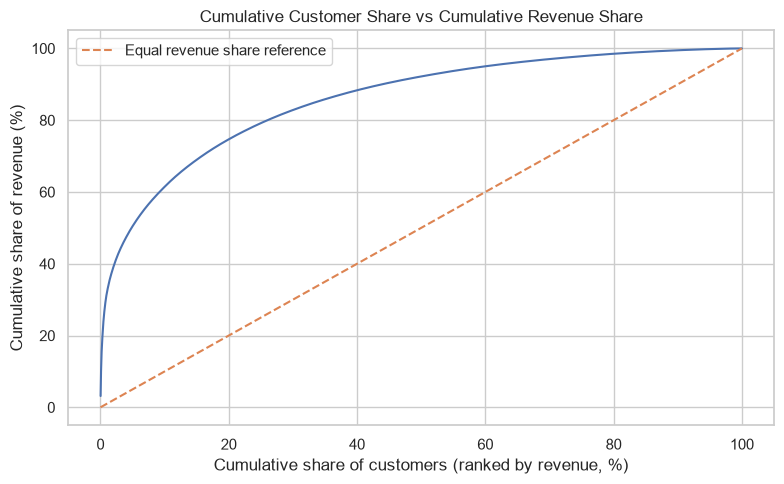

In [16]:
ranked = customer_summary.sort_values("revenue", ascending=False).reset_index(drop=True)
ranked["customer_rank"] = np.arange(1, len(ranked) + 1)
ranked["cumulative_revenue_share_pct"] = ranked["revenue"].cumsum() / ranked["revenue"].sum() * 100
ranked["cumulative_customer_share_pct"] = ranked["customer_rank"] / len(ranked) * 100

top_10_count = max(1, int(np.ceil(len(ranked) * 0.10)))
top_10_revenue_share = ranked.head(top_10_count)["revenue"].sum() / ranked["revenue"].sum() * 100
top_20_count = max(1, int(np.ceil(len(ranked) * 0.20)))
top_20_revenue_share = ranked.head(top_20_count)["revenue"].sum() / ranked["revenue"].sum() * 100

print(f"Top 10% of customers account for {top_10_revenue_share:.1f}% of analyzed revenue.")
print(f"Top 20% of customers account for {top_20_revenue_share:.1f}% of analyzed revenue.")

plt.figure(figsize=(8, 5))
plt.plot(ranked["cumulative_customer_share_pct"], ranked["cumulative_revenue_share_pct"])
plt.plot([0, 100], [0, 100], linestyle="--", label="Equal revenue share reference")
plt.title("Cumulative Customer Share vs Cumulative Revenue Share")
plt.xlabel("Cumulative share of customers (ranked by revenue, %)")
plt.ylabel("Cumulative share of revenue (%)")
plt.legend()
plt.tight_layout()
plt.savefig(str(FIGURE_DIR / "customer_revenue_concentration.png"), dpi=160)
plt.show()


## 7. Revenue by month

This chart shows how the recorded revenue changes from month to month. It shows the pattern in the data, but it does not tell us what caused any increase or decrease.

,InvoiceMonth,revenue,invoices,customers
0,2010-12,570422.730,1400,885
1,2011-01,568101.310,987,741
2,2011-02,446084.920,997,758
3,2011-03,594081.760,1321,974
4,2011-04,468374.331,1149,856
5,2011-05,677355.150,1555,1056
6,2011-06,660046.050,1393,991
7,2011-07,598962.901,1331,949
8,2011-08,644051.040,1280,935
9,2011-09,950690.202,1755,1266


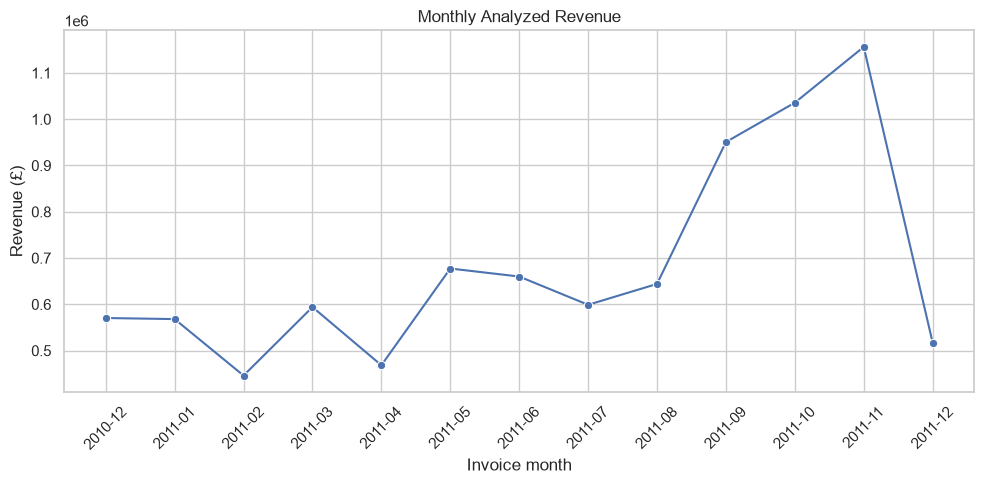

In [17]:
monthly = sales.groupby("InvoiceMonth", as_index=False).agg(
    revenue=("Revenue", "sum"),
    invoices=("InvoiceNo", "nunique"),
    customers=("CustomerID", "nunique")
)
display(monthly)

plt.figure(figsize=(10, 5))
sns.lineplot(data=monthly, x="InvoiceMonth", y="revenue", marker="o")
plt.title("Monthly Analyzed Revenue")
plt.xlabel("Invoice month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(str(FIGURE_DIR / "monthly_revenue.png"), dpi=160)
plt.show()


## 8. Products and countries

I also look at the products and countries with the highest recorded revenue. These are extra details to help understand the dataset. Revenue is not the same as profit because product costs are not included.

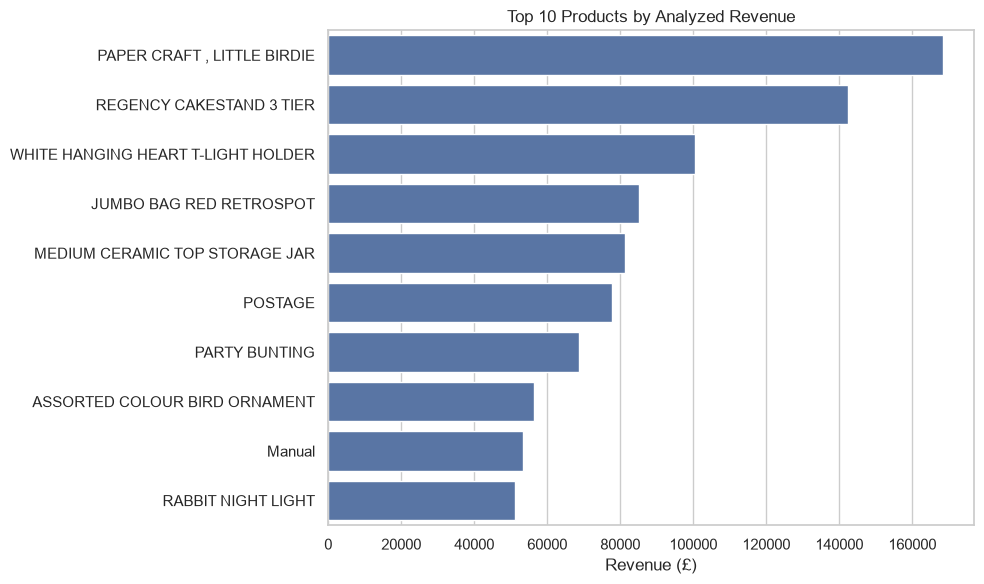

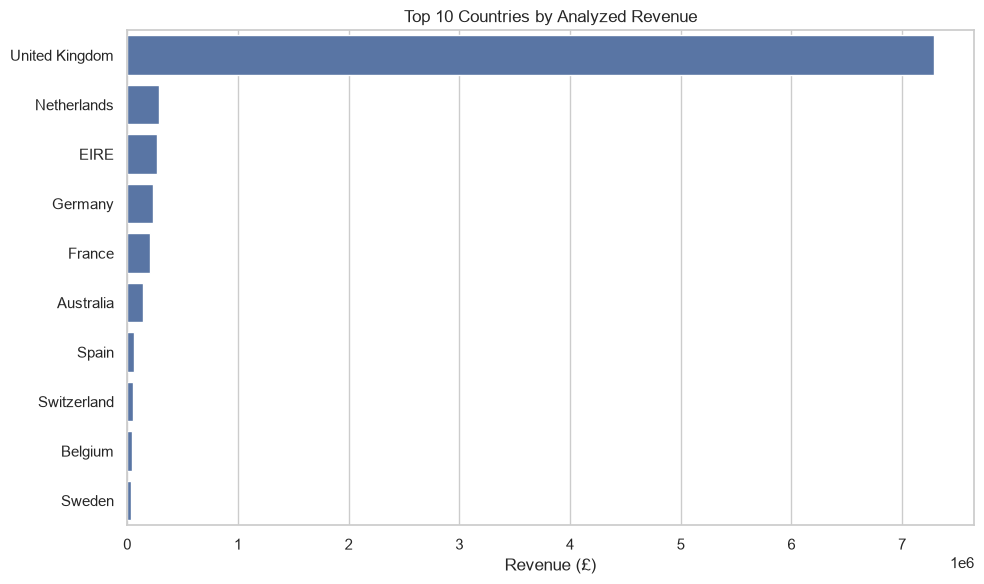

In [18]:
top_products = (sales.groupby("Description", as_index=False)["Revenue"]
                .sum().sort_values("Revenue", ascending=False).head(10))
plt.figure(figsize=(10, 6))
sns.barplot(data=top_products, y="Description", x="Revenue")
plt.title("Top 10 Products by Analyzed Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("")
plt.tight_layout()
plt.savefig(str(FIGURE_DIR / "top_products.png"), dpi=160)
plt.show()

top_countries = (sales.groupby("Country", as_index=False)["Revenue"]
                 .sum().sort_values("Revenue", ascending=False).head(10))
plt.figure(figsize=(10, 6))
sns.barplot(data=top_countries, y="Country", x="Revenue")
plt.title("Top 10 Countries by Analyzed Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("")
plt.tight_layout()
plt.savefig(str(FIGURE_DIR / "top_countries.png"), dpi=160)
plt.show()


## 9. Save the results

This cell saves the summary tables as CSV files and saves the charts in the `outputs/figures` folder.

In [19]:
customer_summary.to_csv(OUTPUT_DIR / "customer_summary.csv", index=False)
monthly.to_csv(OUTPUT_DIR / "monthly_summary.csv", index=False)
type_summary.to_csv(OUTPUT_DIR / "customer_type_summary.csv")
print("Saved summaries and figures to the outputs folder.")


Saved summaries and figures to the outputs folder.


## 10. My finding

From the results, repeat customers made up **65.6%** of the customers and contributed **93.1%** of the analyzed revenue. The top 10% of customers contributed **61.5%** of the analyzed revenue.

This suggests that repeat customers are important to this retailer's sales, and a large part of the revenue also comes from a smaller group of high-spending customers. The business could try a simple loyalty offer and compare repeat purchases before and after the offer to see whether it helps.

**Limitations:** This analysis covers only the dates in this dataset. Rows without customer IDs, cancelled invoices, duplicate rows, and sales rows with invalid quantity or price were excluded. Revenue is not profit, and these results do not prove that a loyalty offer would increase sales.


## Dataset source

Chen, D. (2012). *Online Retail* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33

Dataset page: https://archive.ics.uci.edu/dataset/352/online+retail